# Clasificador de imágenes con Teachable Machine: cartera y cascos

**Autor:** [Iván Gómez Carmona]
**Ciclo:** Desarrollo de Aplicaciones Multiplataforma 


## Índice
1. Objetivo
2. Crear y entrenar el modelo
3. Probar el modelo
4. Exportar el modelo (JavaScript y Python)
5. Crear la página web y probarla con Live Server
6. Mejora del HTML y CSS
7. Probar el modelo en Python (Colab)
8. Problemas encontrados y soluciones
9. Conclusiones
10. Anexo: código completo

## 1. Objetivo

El objetivo es crear con **Teachable Machine** un modelo que distinga entre dos objetos, una **cartera** y unos **cascos**, y usarlo de dos formas:

- En una **página web** (HTML, CSS y JavaScript) que usa la cámara y dice qué objeto ve, gracias a TensorFlow.js.
- En **Python**, exportando el mismo modelo en formato Keras y probándolo en este cuaderno de Colab.

## 2. Crear y entrenar el modelo

Entramos en [teachablemachine.withgoogle.com](https://teachablemachine.withgoogle.com) y creamos un **proyecto de imágenes**. Creamos dos clases, una por cada objeto:

- **cartera**: 69 muestras de imágenes.
- **cascos**: 109 muestras de imágenes.

Las muestras se hicieron con la cámara web, moviendo el objeto para tener distintos ángulos y distancias. Después pulsamos **Entrenar modelo**.

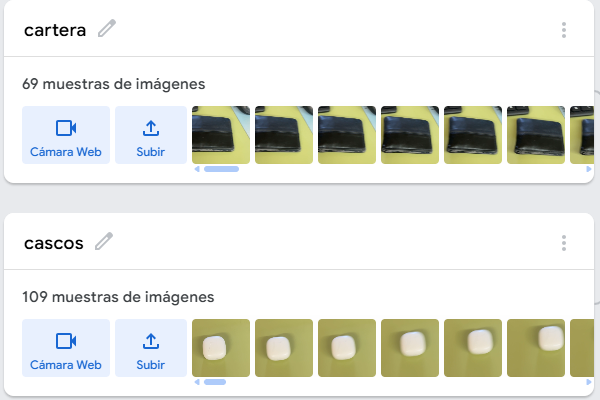

## 3. Probar el modelo

Con el modelo entrenado usamos la **Vista previa** con la cámara web. Al enseñar los cascos, la barra de *cascos* llega al **100 %**:

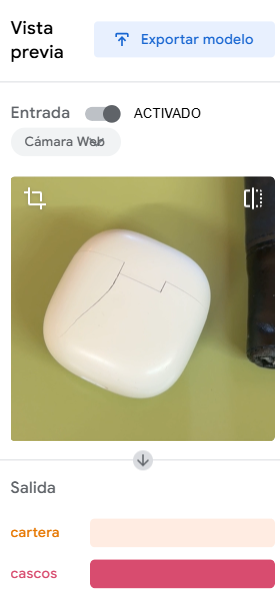

Y si enseñamos la cartera ocurre lo mismo con la barra de *cartera*:

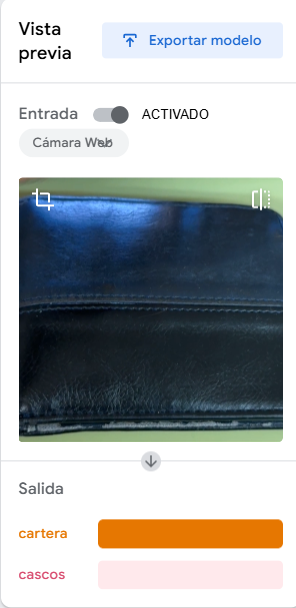

Con esto comprobamos que el modelo distingue bien los dos objetos antes de exportarlo.

## 4. Exportar el modelo (JavaScript y Python)

Pulsamos **Exportar modelo**. Lo exportamos en dos formatos, porque lo vamos a usar de dos maneras.

### 4.1 TensorFlow.js (para la página web)
En la pestaña **Tensorflow.js** elegimos *Descargar* y copiamos el **código de ejemplo** que da Teachable Machine, para usarlo después como base de nuestra página. El `.zip` descargado contiene `model.json`, `metadata.json` y `weights.bin`.

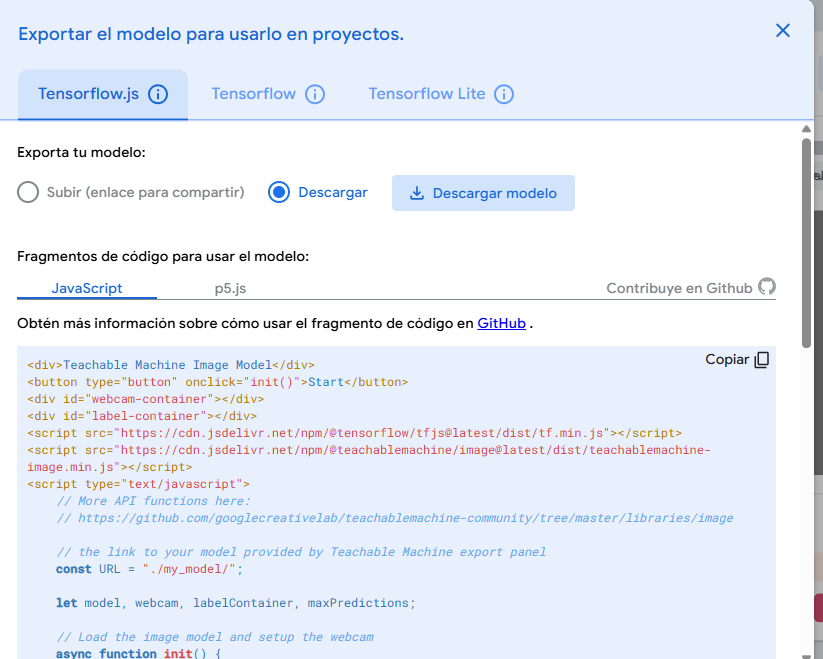

### 4.2 TensorFlow / Keras (para Python)
En la pestaña **Tensorflow** elegimos el tipo **Keras** y descargamos el modelo, que es un archivo `keras_Model.h5` junto con `labels.txt` (los nombres de las clases). También copiamos el código en Python que muestra la pantalla, que usamos en el apartado 7.

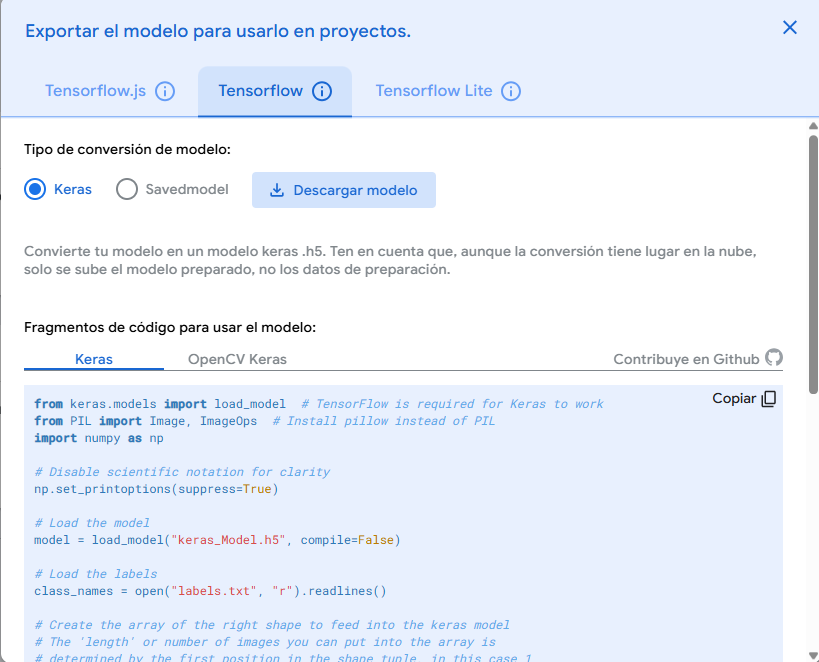

## 5. Crear la página web y probarla con Live Server

Creamos en Visual Studio Code los tres archivos del proyecto: `index.html`, `style.css` y `app.js`, junto a la carpeta del modelo `my_model`. Pegamos el código de JavaScript copiado antes en `app.js`.

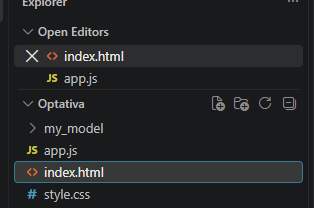

Para probarla abrimos `index.html` con **Live Server** (clic derecho → *Open with Live Server*). Hay que usar un servidor porque, si el HTML se abre con doble clic, el navegador bloquea la cámara y la carga del modelo. Al pulsar *Start*, el navegador pide permiso para usar la cámara y la página muestra qué objeto ve. En la captura, al enseñar la cartera, aparece **cartera: 1.00** y **cascos: 0.00**:

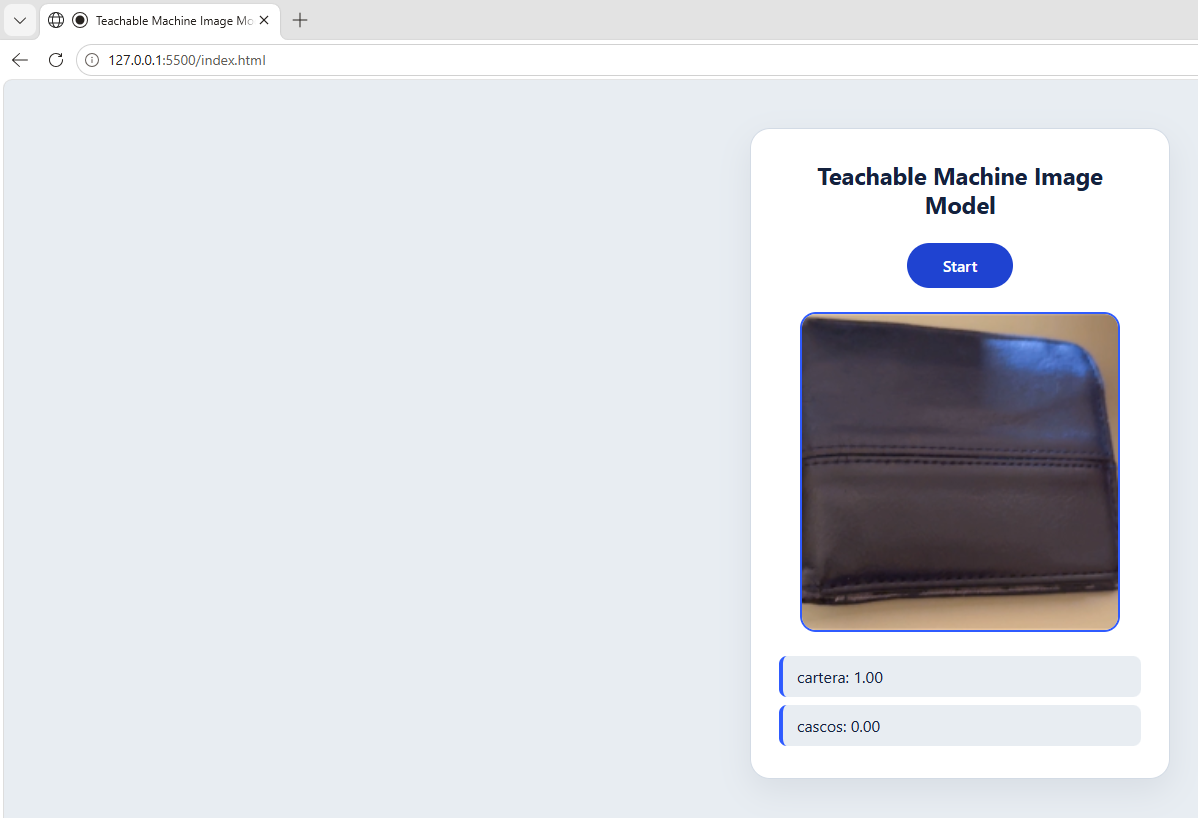

## 6. Mejora del HTML y CSS

Después mejoramos el diseño y añadimos funciones nuevas. La página queda así:

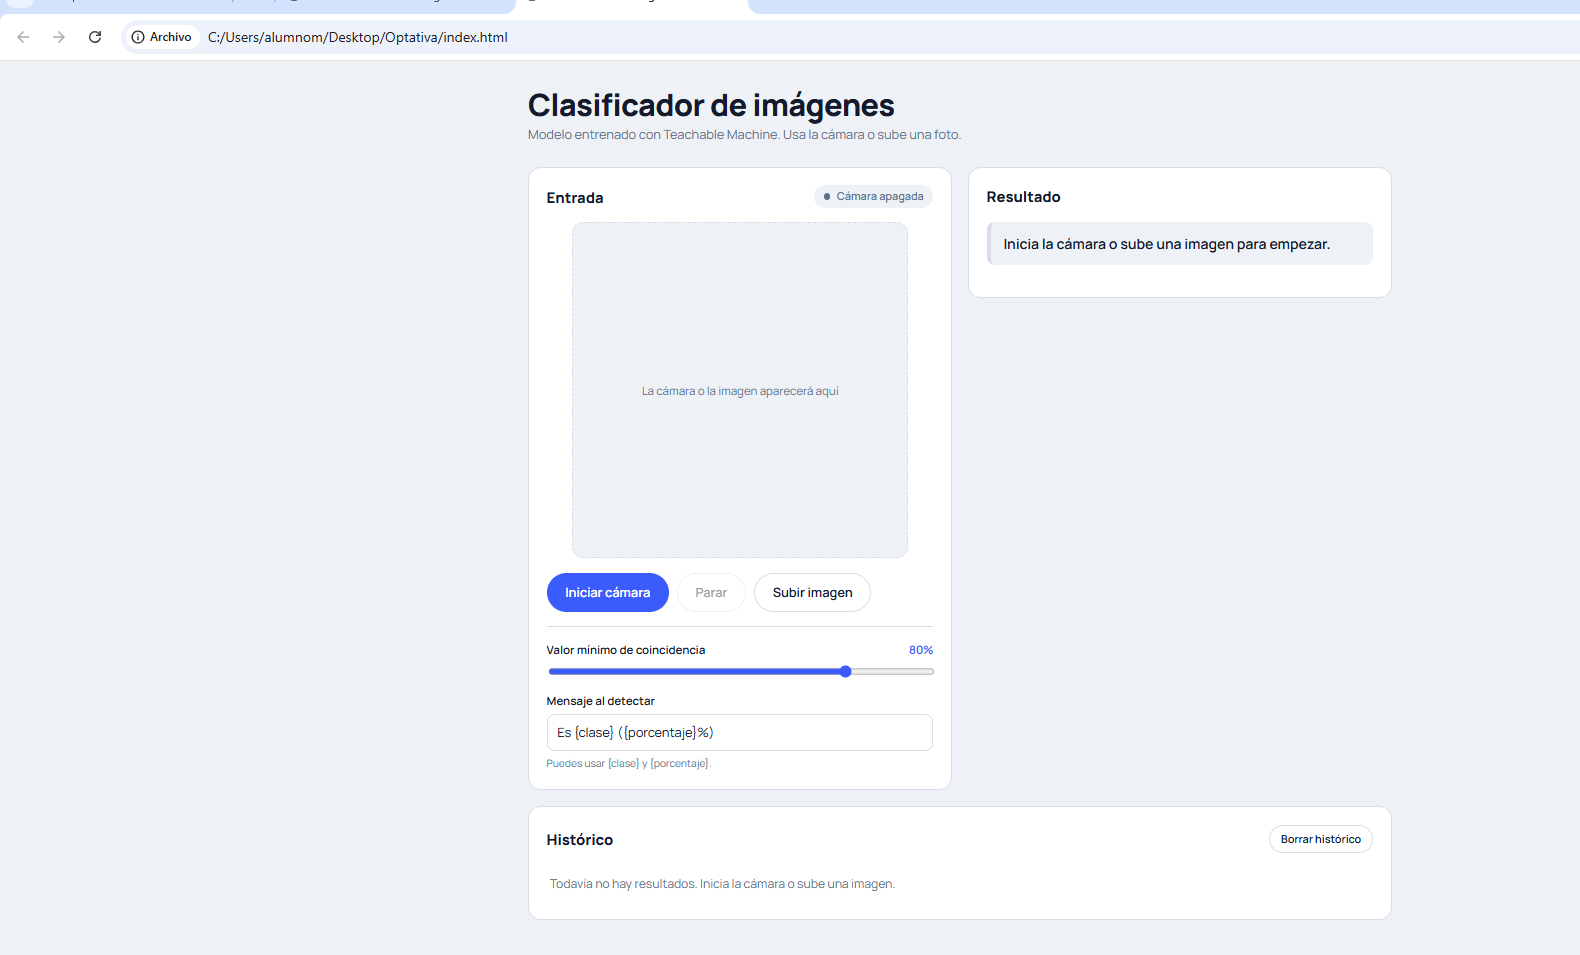

**Diseño (HTML y CSS)**
- Tres paneles: *Entrada* (visor, botones y ajustes), *Resultado* (mensaje y barras) e *Histórico*.
- Diseño **responsive** con CSS Grid: en móvil va en una columna y en pantallas de más de 860 px, en dos.
- Las barras de resultado tienen una marca que indica el valor mínimo, y la clase ganadora se pone en verde.

**Funciones nuevas (JavaScript)**
- Botones **Iniciar cámara** y **Parar**: parar apaga la cámara de verdad y vacía los resultados.
- **Mensaje personalizado** de salida con `{clase}` y `{porcentaje}`.
- **Valor mínimo** de coincidencia con un deslizador: solo se considera coincidencia si la clase ganadora lo supera.
- **Histórico** de resultados (clase, porcentaje, origen y hora), guardado en `localStorage`.
- **Subir una imagen** para clasificarla.

```js
// Comparación con el valor mínimo (función predecir)
const minimo = Number(umbral.value) / 100;
const hayCoincidencia = mejor.probability >= minimo;
```

## 7. Probar el modelo en Python (Colab)

Ahora usamos el modelo que exportamos en formato **Keras**. Para ello:

1. Subimos a Colab `keras_Model.h5`, `labels.txt` y una foto de prueba (de una cartera o unos cascos).
2. Cargamos el modelo, preparamos la imagen (224 × 224 píxeles y valores normalizados entre -1 y 1) y le pedimos una predicción.

In [ ]:
# Paso 1: sube keras_Model.h5, labels.txt y una imagen de prueba
from google.colab import files
subidos = files.upload()
print("Archivos subidos:", list(subidos.keys()))

In [ ]:
# Paso 2: cargar el modelo y clasificar la imagen
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np

np.set_printoptions(suppress=True)

RUTA_IMAGEN = "prueba.jpg"   # <- cambia por el nombre de tu imagen

# Cargar el modelo y los nombres de las clases
model = load_model("keras_Model.h5", compile=False)
class_names = open("labels.txt", "r").readlines()

# Preparar la imagen: 224x224 y normalizada entre -1 y 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
image = Image.open(RUTA_IMAGEN).convert("RGB")
image = ImageOps.fit(image, (224, 224), Image.Resampling.LANCZOS)
image_array = np.asarray(image)
data[0] = (image_array.astype(np.float32) / 127.5) - 1

# Predecir
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

print("Clase:", class_name[2:].strip())
print("Seguridad:", round(float(confidence_score) * 100, 2), "%")
display(image)

> ⚠️ **Si `load_model` da un error con `DepthwiseConv2D` / `groups`:** es un problema conocido de compatibilidad entre los modelos de Teachable Machine y las versiones nuevas de Keras. Se soluciona cargando el modelo así, en lugar de la línea `model = load_model(...)`:
>
> ```python
> from keras.layers import DepthwiseConv2D
>
> class DepthwiseConv2DCompat(DepthwiseConv2D):
>     def __init__(self, **kwargs):
>         kwargs.pop("groups", None)
>         super().__init__(**kwargs)
>
> model = load_model("keras_Model.h5", compile=False,
>                    custom_objects={"DepthwiseConv2D": DepthwiseConv2DCompat})
> ```

> 📷 **Captura pendiente 7:** Resultado de la celda de Python en Colab: la imagen de prueba, la clase detectada y su porcentaje.
>
> *(pega aquí la captura con Ctrl+V y borra esta línea)*

## 8. Problemas encontrados y soluciones

| Problema | Causa | Solución |
|---|---|---|
| El editor marcaba errores en todo `app.js` | Había pegado etiquetas HTML (`<div>`, `<button>`, `<script>`) dentro del archivo `.js`, que solo admite JavaScript | Separar el código: HTML en `index.html` y solo JavaScript en `app.js` |
| Conflicto con la constante `URL` | `URL` ya existe en el navegador | Renombrarla a `MODEL_URL` |
| La cámara no aparecía al pulsar Start | La ruta de la carpeta del modelo no coincidía con el nombre real de la carpeta | Hacer coincidir la ruta de `MODEL_URL` con el nombre de la carpeta (`my_model`) |
| La cámara no funcionaba al abrir el HTML con doble clic | El navegador bloquea la cámara y el modelo con `file://` | Abrir el proyecto con Live Server |

## 9. Conclusiones

Hemos comprobado que con Teachable Machine se puede entrenar un modelo de clasificación de imágenes sin programar y llevarlo después a una página web (TensorFlow.js) o a Python (Keras). También hemos practicado la separación de HTML, CSS y JavaScript, el diseño responsive y el uso de la cámara desde el navegador.

Posibles mejoras: usar un número de imágenes parecido en las dos clases (69 de cartera frente a 109 de cascos), añadir más variedad de fondos e iluminación, y añadir más objetos.

[COMPLETA: tu valoración personal, qué has aprendido y qué te ha costado más]

## 10. Anexo: código completo

### index.html

```html
<!DOCTYPE html>
<html lang="es">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <title>Clasificador de imágenes · Teachable Machine</title>
    <link rel="preconnect" href="https://fonts.googleapis.com">
    <link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
    <link href="https://fonts.googleapis.com/css2?family=Manrope:wght@400;500;600;800&display=swap" rel="stylesheet">
    <link rel="stylesheet" href="style.css">
</head>
<body>
    <header class="cabecera">
        <h1>Clasificador de imágenes</h1>
        <p>Modelo entrenado con Teachable Machine. Usa la cámara o sube una foto.</p>
    </header>

    <main class="rejilla">

        <!-- ENTRADA: cámara / imagen y ajustes -->
        <section class="panel" aria-labelledby="t-entrada">
            <div class="panel-cab">
                <h2 id="t-entrada">Entrada</h2>
                <span id="estado" class="estado" data-activo="false">Cámara apagada</span>
            </div>

            <div id="webcam-container"></div>

            <div class="acciones">
                <button id="btn-iniciar" class="btn primario" type="button">Iniciar cámara</button>
                <button id="btn-parar" class="btn secundario" type="button" disabled>Parar</button>
                <button id="btn-subir" class="btn secundario" type="button">Subir imagen</button>
                <input id="archivo" type="file" accept="image/*" hidden>
            </div>

            <div class="ajustes">
                <div class="campo">
                    <label for="umbral">
                        Valor mínimo de coincidencia
                        <output id="umbral-valor" for="umbral">80%</output>
                    </label>
                    <input id="umbral" type="range" min="10" max="100" step="1" value="80">
                </div>

                <div class="campo">
                    <label for="plantilla">Mensaje al detectar</label>
                    <input id="plantilla" type="text" value="Es {clase} ({porcentaje}%)">
                    <small>Puedes usar {clase} y {porcentaje}.</small>
                </div>
            </div>
        </section>

        <!-- RESULTADO: mensaje + barras de probabilidad -->
        <section class="panel" aria-labelledby="t-resultado">
            <div class="panel-cab">
                <h2 id="t-resultado">Resultado</h2>
            </div>

            <p id="mensaje" data-tipo="neutro" aria-live="polite">
                Inicia la cámara o sube una imagen para empezar.
            </p>

            <div id="label-container"></div>
        </section>

        <!-- HISTORIAL -->
        <section class="panel historial" aria-labelledby="t-historial">
            <div class="panel-cab">
                <h2 id="t-historial">Histórico</h2>
                <button id="btn-borrar" class="btn secundario pequeno" type="button">Borrar histórico</button>
            </div>
            <ul id="historial"></ul>
        </section>

    </main>

    <script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@latest/dist/tf.min.js"></script>
    <script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@latest/dist/teachablemachine-image.min.js"></script>
    <script src="app.js"></script>
</body>
</html>
```

### style.css

```css
:root {
    --fondo: #eef1f6;
    --tarjeta: #ffffff;
    --tinta: #121a2b;
    --suave: #61708a;
    --borde: #d6dde8;
    --acento: #3b5bfd;
    --acento-oscuro: #2a43d1;
    --ok: #12a150;
    --ok-fondo: #e6f6ed;
    --aviso: #c97a00;
    --aviso-fondo: #fff3de;
    --error: #d6336c;
    --error-fondo: #fde8ef;
}

* {
    box-sizing: border-box;
}

body {
    margin: 0;
    padding: 32px 16px 48px;
    background: var(--fondo);
    color: var(--tinta);
    font-family: "Manrope", "Segoe UI", system-ui, sans-serif;
    line-height: 1.5;
}

/* ---------- Cabecera ---------- */
.cabecera {
    max-width: 1080px;
    margin: 0 auto 28px;
}

.cabecera h1 {
    margin: 0 0 4px;
    font-size: clamp(1.6rem, 4vw, 2.4rem);
    font-weight: 800;
    letter-spacing: -0.02em;
    line-height: 1.15;
}

.cabecera p {
    margin: 0;
    color: var(--suave);
}

/* ---------- Rejilla (responsive) ---------- */
.rejilla {
    max-width: 1080px;
    margin: 0 auto;
    display: grid;
    grid-template-columns: 1fr;
    gap: 20px;
}

@media (min-width: 860px) {
    .rejilla {
        grid-template-columns: 1fr 1fr;
        align-items: start;
    }

    .historial {
        grid-column: 1 / -1;
    }
}

/* ---------- Paneles ---------- */
.panel {
    background: var(--tarjeta);
    border: 1px solid var(--borde);
    border-radius: 16px;
    padding: 22px;
    display: flex;
    flex-direction: column;
    gap: 18px;
}

.panel-cab {
    display: flex;
    justify-content: space-between;
    align-items: center;
    gap: 12px;
    flex-wrap: wrap;
}

.panel h2 {
    margin: 0;
    font-size: 1.15rem;
    font-weight: 800;
}

/* ---------- Estado ---------- */
.estado {
    display: inline-flex;
    align-items: center;
    gap: 8px;
    padding: 4px 12px;
    background: var(--fondo);
    border-radius: 999px;
    font-size: 0.85rem;
    font-weight: 600;
    color: var(--suave);
}

.estado::before {
    content: "";
    width: 8px;
    height: 8px;
    border-radius: 50%;
    background: var(--suave);
}

.estado[data-activo="true"] {
    color: var(--ok);
    background: var(--ok-fondo);
}

.estado[data-activo="true"]::before {
    background: var(--ok);
}

/* ---------- Visor (cámara o imagen) ---------- */
#webcam-container {
    width: min(100%, 420px);
    aspect-ratio: 1 / 1;
    margin-inline: auto;
    display: flex;
    justify-content: center;
    align-items: center;
    background: var(--fondo);
    border: 2px dashed var(--borde);
    border-radius: 14px;
    overflow: hidden;
}

#webcam-container:empty::before {
    content: "La cámara o la imagen aparecerá aquí";
    padding: 0 24px;
    text-align: center;
    color: var(--suave);
    font-size: 0.9rem;
}

#webcam-container:not(:empty) {
    border: 2px solid var(--acento);
}

/* El canvas de la cámara se escala para llenar el visor */
#webcam-container canvas {
    width: 100% !important;
    height: 100% !important;
    object-fit: cover;
    display: block;
}

/* La imagen subida se ve entera, sin recortar */
#webcam-container img {
    width: 100%;
    height: 100%;
    object-fit: contain;
    display: block;
    background: #fff;
}

/* ---------- Botones ---------- */
.acciones {
    display: flex;
    flex-wrap: wrap;
    gap: 10px;
}

.btn {
    padding: 11px 22px;
    font: inherit;
    font-weight: 600;
    border: 1.5px solid transparent;
    border-radius: 999px;
    cursor: pointer;
    transition: background 0.15s, border-color 0.15s, transform 0.1s;
}

.btn.primario {
    background: var(--acento);
    color: #fff;
}

.btn.primario:hover:not(:disabled) {
    background: var(--acento-oscuro);
}

.btn.secundario {
    background: var(--tarjeta);
    color: var(--tinta);
    border-color: var(--borde);
}

.btn.secundario:hover:not(:disabled) {
    border-color: var(--tinta);
}

.btn.pequeno {
    padding: 6px 14px;
    font-size: 0.85rem;
}

.btn:active:not(:disabled) {
    transform: scale(0.97);
}

.btn:disabled {
    opacity: 0.45;
    cursor: not-allowed;
}

.btn:focus-visible,
input:focus-visible {
    outline: 3px solid var(--acento);
    outline-offset: 2px;
}

@media (max-width: 480px) {
    .acciones .btn {
        flex: 1 1 100%;
    }
}

/* ---------- Ajustes ---------- */
.ajustes {
    display: grid;
    gap: 16px;
    padding-top: 18px;
    border-top: 1px solid var(--borde);
}

.campo {
    display: flex;
    flex-direction: column;
    gap: 6px;
}

.campo label {
    display: flex;
    justify-content: space-between;
    font-size: 0.9rem;
    font-weight: 600;
}

.campo output {
    color: var(--acento);
    font-variant-numeric: tabular-nums;
}

.campo small {
    color: var(--suave);
    font-size: 0.8rem;
}

.campo input[type="text"] {
    padding: 10px 12px;
    font: inherit;
    border: 1.5px solid var(--borde);
    border-radius: 10px;
    background: var(--tarjeta);
    color: var(--tinta);
}

.campo input[type="range"] {
    width: 100%;
    accent-color: var(--acento);
}

/* ---------- Mensaje de salida ---------- */
#mensaje {
    margin: 0;
    padding: 14px 16px;
    border-left: 5px solid var(--borde);
    border-radius: 10px;
    background: var(--fondo);
    font-size: 1.1rem;
    font-weight: 600;
}

#mensaje[data-tipo="ok"] {
    background: var(--ok-fondo);
    border-left-color: var(--ok);
}

#mensaje[data-tipo="aviso"] {
    background: var(--aviso-fondo);
    border-left-color: var(--aviso);
}

#mensaje[data-tipo="error"] {
    background: var(--error-fondo);
    border-left-color: var(--error);
}

/* ---------- Barras de probabilidad ---------- */
#label-container {
    display: flex;
    flex-direction: column;
    gap: 14px;
}

.fila {
    display: grid;
    grid-template-columns: 1fr auto;
    gap: 6px 12px;
}

.nombre {
    font-weight: 600;
    overflow-wrap: anywhere;
}

.valor {
    font-variant-numeric: tabular-nums;
    color: var(--suave);
    font-weight: 600;
}

.barra {
    grid-column: 1 / -1;
    position: relative;
    height: 10px;
    background: var(--fondo);
    border-radius: 999px;
}

.relleno {
    height: 100%;
    width: 0;
    background: var(--acento);
    border-radius: inherit;
    transition: width 0.15s linear, background 0.15s;
}

/* Marca vertical que indica el valor mínimo */
.barra::after {
    content: "";
    position: absolute;
    top: -4px;
    bottom: -4px;
    left: var(--umbral, 80%);
    width: 2px;
    background: var(--tinta);
    opacity: 0.45;
}

.fila.ganador .relleno {
    background: var(--ok);
}

.fila.ganador .nombre,
.fila.ganador .valor {
    color: var(--ok);
}

/* ---------- Histórico ---------- */
#historial {
    list-style: none;
    margin: 0;
    padding: 0;
    max-height: 320px;
    overflow-y: auto;
    display: flex;
    flex-direction: column;
}

#historial li {
    display: grid;
    grid-template-columns: 1fr auto auto auto;
    gap: 4px 16px;
    align-items: center;
    padding: 10px 4px;
    border-bottom: 1px solid var(--borde);
    font-size: 0.95rem;
}

#historial li:last-child {
    border-bottom: none;
}

#historial .h-clase {
    font-weight: 700;
}

#historial .h-pct {
    color: var(--ok);
    font-weight: 700;
    font-variant-numeric: tabular-nums;
}

#historial .h-origen,
#historial .h-hora {
    color: var(--suave);
    font-size: 0.85rem;
    font-variant-numeric: tabular-nums;
}

#historial li.vacio {
    display: block;
    color: var(--suave);
    border-bottom: none;
}

@media (max-width: 560px) {
    #historial li {
        grid-template-columns: 1fr auto;
    }
}

@media (prefers-reduced-motion: reduce) {
    * {
        transition: none !important;
    }
}
```

### app.js

```javascript
// Ruta de la carpeta del modelo (la que descargas de Teachable Machine).
// Si tu carpeta se llama distinto (por ejemplo "Modelo"), cámbialo aquí.
const MODEL_URL = "./my_model/";

const MAX_HISTORIAL = 30;
const CLAVE_HISTORIAL = "historial-clasificador";

let model, webcam, maxPredictions;
let filas = [];               // referencias a las filas de barras
let animacion = null;         // id del requestAnimationFrame
let camaraActiva = false;
let ultimaCoincidencia = null; // para no repetir en el histórico cada fotograma
let historial = [];

// ---------- Elementos del DOM ----------
const visor = document.getElementById("webcam-container");
const labelContainer = document.getElementById("label-container");
const mensaje = document.getElementById("mensaje");
const estado = document.getElementById("estado");
const btnIniciar = document.getElementById("btn-iniciar");
const btnParar = document.getElementById("btn-parar");
const btnSubir = document.getElementById("btn-subir");
const btnBorrar = document.getElementById("btn-borrar");
const archivo = document.getElementById("archivo");
const umbral = document.getElementById("umbral");
const umbralValor = document.getElementById("umbral-valor");
const plantilla = document.getElementById("plantilla");
const listaHistorial = document.getElementById("historial");

// ---------- Utilidades de interfaz ----------
function mostrarMensaje(texto, tipo) {
    mensaje.textContent = texto;
    mensaje.dataset.tipo = tipo;
}

function setEstado(texto, activo) {
    estado.textContent = texto;
    estado.dataset.activo = activo ? "true" : "false";
}

function actualizarBotones() {
    btnIniciar.disabled = camaraActiva;
    btnParar.disabled = !camaraActiva;
}

function limpiarVisor() {
    visor.innerHTML = "";
}

function actualizarUmbral() {
    umbralValor.textContent = umbral.value + "%";
    labelContainer.style.setProperty("--umbral", umbral.value + "%");
}

// ---------- Modelo ----------
async function cargarModelo() {
    if (model) return;
    setEstado("Cargando modelo...", false);
    model = await tmImage.load(MODEL_URL + "model.json", MODEL_URL + "metadata.json");
    maxPredictions = model.getTotalClasses();
    crearFilas(model.getClassLabels());
}

function crearFilas(nombres) {
    labelContainer.innerHTML = "";
    filas = nombres.map((nombre) => {
        const el = document.createElement("div");
        el.className = "fila";
        el.innerHTML =
            '<span class="nombre"></span><span class="valor">0%</span>' +
            '<div class="barra"><div class="relleno"></div></div>';
        el.querySelector(".nombre").textContent = nombre;
        labelContainer.appendChild(el);
        return {
            el,
            valor: el.querySelector(".valor"),
            relleno: el.querySelector(".relleno"),
        };
    });
    actualizarUmbral();
}

function reiniciarBarras() {
    filas.forEach((f) => {
        f.relleno.style.width = "0%";
        f.valor.textContent = "0%";
        f.el.classList.remove("ganador");
    });
}

// ---------- Cámara ----------
async function iniciar() {
    if (camaraActiva) return;
    btnIniciar.disabled = true;
    try {
        await cargarModelo();
        limpiarVisor();

        const flip = true;
        webcam = new tmImage.Webcam(400, 400, flip);
        await webcam.setup();
        await webcam.play();
        visor.appendChild(webcam.canvas);

        camaraActiva = true;
        ultimaCoincidencia = null;
        setEstado("Cámara activa", true);
        mostrarMensaje("Analizando...", "neutro");
        actualizarBotones();
        animacion = window.requestAnimationFrame(loop);
    } catch (error) {
        console.error(error);
        camaraActiva = false;
        setEstado("Cámara apagada", false);
        mostrarMensaje(
            "No se pudo iniciar. Revisa la ruta del modelo y el permiso de la cámara.",
            "error"
        );
        actualizarBotones();
    }
}

function parar() {
    if (!camaraActiva) return;
    camaraActiva = false;
    window.cancelAnimationFrame(animacion);
    webcam.stop();
    limpiarVisor();
    reiniciarBarras();
    ultimaCoincidencia = null;
    setEstado("Cámara apagada", false);
    mostrarMensaje("Cámara parada. Pulsa Iniciar o sube una imagen.", "neutro");
    actualizarBotones();
}

async function loop() {
    if (!camaraActiva) return;
    webcam.update();
    await predecir(webcam.canvas, "Cámara");
    if (camaraActiva) {
        animacion = window.requestAnimationFrame(loop);
    }
}

// ---------- Predicción ----------
async function predecir(fuente, origen) {
    const prediccion = await model.predict(fuente);

    let mejor = prediccion[0];
    prediccion.forEach((p) => {
        if (p.probability > mejor.probability) mejor = p;
    });

    const minimo = Number(umbral.value) / 100;
    const hayCoincidencia = mejor.probability >= minimo;

    prediccion.forEach((p, i) => {
        const porcentaje = Math.round(p.probability * 100);
        filas[i].relleno.style.width = porcentaje + "%";
        filas[i].valor.textContent = porcentaje + "%";
        filas[i].el.classList.toggle("ganador", hayCoincidencia && p === mejor);
    });

    if (hayCoincidencia) {
        const porcentaje = Math.round(mejor.probability * 100);
        const texto = plantilla.value
            .replaceAll("{clase}", mejor.className)
            .replaceAll("{porcentaje}", porcentaje);
        mostrarMensaje(texto, "ok");

        if (mejor.className !== ultimaCoincidencia) {
            registrar(mejor.className, porcentaje, origen);
            ultimaCoincidencia = mejor.className;
        }
    } else {
        mostrarMensaje(
            "Sin coincidencia clara (mínimo " + umbral.value + "%).",
            "aviso"
        );
        ultimaCoincidencia = null;
    }
}

// ---------- Subir imagen ----------
async function subirImagen() {
    const fichero = archivo.files[0];
    archivo.value = "";
    if (!fichero) return;

    if (!fichero.type.startsWith("image/")) {
        mostrarMensaje("El archivo no es una imagen.", "error");
        return;
    }

    if (camaraActiva) parar();

    const url = URL.createObjectURL(fichero);
    try {
        await cargarModelo();
        const img = new Image();
        img.src = url;
        await img.decode();

        limpiarVisor();
        visor.appendChild(img);
        setEstado("Imagen cargada", false);

        ultimaCoincidencia = null;
        await predecir(img, "Imagen");
    } catch (error) {
        console.error(error);
        mostrarMensaje("No se pudo analizar la imagen.", "error");
    } finally {
        URL.revokeObjectURL(url);
    }
}

// ---------- Histórico ----------
function cargarHistorial() {
    try {
        const guardado = JSON.parse(localStorage.getItem(CLAVE_HISTORIAL));
        if (Array.isArray(guardado)) historial = guardado;
    } catch (error) {
        historial = [];
    }
}

function guardarHistorial() {
    try {
        localStorage.setItem(CLAVE_HISTORIAL, JSON.stringify(historial));
    } catch (error) {
        console.warn("No se pudo guardar el histórico", error);
    }
}

function registrar(clase, porcentaje, origen) {
    historial.unshift({
        clase,
        porcentaje,
        origen,
        hora: new Date().toLocaleTimeString("es-ES"),
    });
    historial = historial.slice(0, MAX_HISTORIAL);
    guardarHistorial();
    pintarHistorial();
}

function pintarHistorial() {
    listaHistorial.innerHTML = "";

    if (historial.length === 0) {
        const vacio = document.createElement("li");
        vacio.className = "vacio";
        vacio.textContent = "Todavía no hay resultados. Inicia la cámara o sube una imagen.";
        listaHistorial.appendChild(vacio);
        return;
    }

    historial.forEach((h) => {
        const li = document.createElement("li");
        const datos = [
            ["h-clase", h.clase],
            ["h-pct", h.porcentaje + "%"],
            ["h-origen", h.origen],
            ["h-hora", h.hora],
        ];
        datos.forEach(([clase, texto]) => {
            const span = document.createElement("span");
            span.className = clase;
            span.textContent = texto;
            li.appendChild(span);
        });
        listaHistorial.appendChild(li);
    });
}

// ---------- Eventos ----------
btnIniciar.addEventListener("click", iniciar);
btnParar.addEventListener("click", parar);
btnSubir.addEventListener("click", () => archivo.click());
archivo.addEventListener("change", subirImagen);
umbral.addEventListener("input", actualizarUmbral);
btnBorrar.addEventListener("click", () => {
    historial = [];
    guardarHistorial();
    pintarHistorial();
});

// ---------- Arranque ----------
actualizarUmbral();
cargarHistorial();
pintarHistorial();
```